# **Seminar 3. Exploratory Data Analysis - Solutions**

### Case: a trade and investment mission to Belgium (continued)

Dataset: `Labour.csv`, 569 Belgian production units, cross-section for 1996.
Source of the data: https://rdrr.io/cran/Ecdat/man/Labour.html
Original reference: Verbeek M. (2004) A Guide to Modern Econometrics, John Wiley and Sons, chapter 4.

Units: `capital` and `output` in millions of euro, `labour` in persons, `wage` in thousands of euro per worker.

Every task below states the correct answer explicitly, followed by the commentary that
the answer is expected to contain.

In [8]:
# 0. Setup: the cell given to the students in "Before you start"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Labour.csv")

# Size bands by the number of workers: fewer than 50, 50 to 249, 250 or more
df["size_band"] = pd.cut(df["labour"], bins=[0, 50, 250, np.inf],
                         labels=["Small", "Medium", "Large"],
                         right=False)

# The order of the size bands, from small to large
size_order = ["Small", "Medium", "Large"]

print(df.shape)
df.head()

(569, 5)


,capital,labour,output,wage,size_band
0,2.606563,184,9.250759,43.080307,Medium
1,1.323237,91,3.664310,27.780016,Medium
2,22.093692,426,28.781516,44.467748,Large
3,10.737851,72,4.124642,39.734710,Medium
4,1.161365,46,2.890150,34.650709,Small


### Task 1. How much does a worker cost?

Create a figure with two panels side by side. On the left panel draw a histogram of `wage`
with 20 bins, on the right panel a box plot of `wage`. Give each panel a title and axis labels.

*Question:* between which values does the middle half of the wages lie? Are there dots beyond
the whiskers, and on which side are most of them?

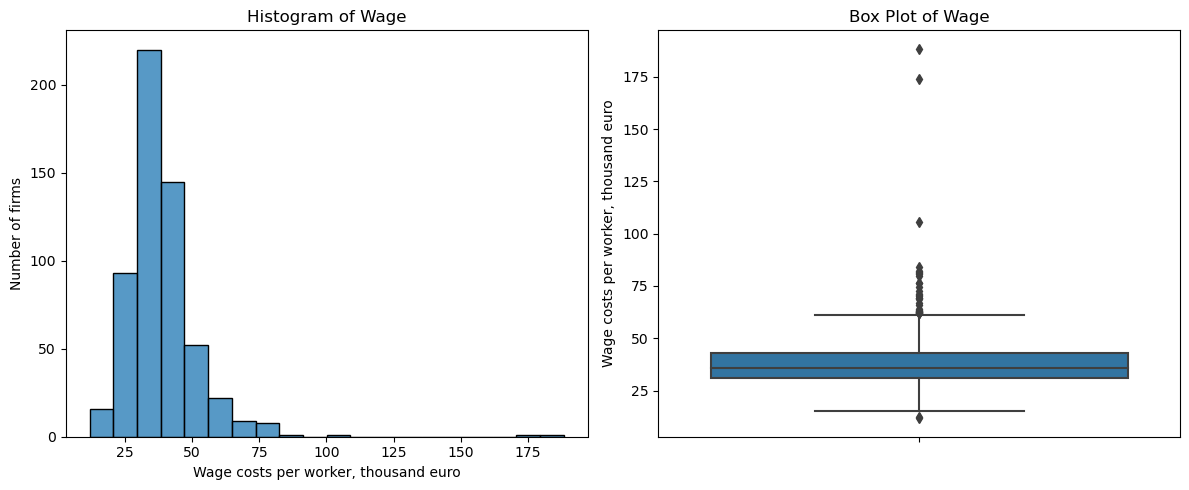

In [9]:
# 1. Histogram and box plot of wage, side by side (demo 2.1 and 2.2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["wage"], bins=20, ax=axes[0])
axes[0].set_title("Histogram of Wage")
axes[0].set_xlabel("Wage costs per worker, thousand euro")
axes[0].set_ylabel("Number of firms")

sns.boxplot(y=df["wage"], ax=axes[1])
axes[1].set_title("Box Plot of Wage")
axes[1].set_ylabel("Wage costs per worker, thousand euro")

plt.tight_layout()
plt.show()

**Correct answer: the middle half of the wages lies between about 31 and 43 thousand euro per worker (Q1 = 30.81, Q3 = 42.90), with the median at about 36. There are dots beyond the whiskers, and almost all of them are above the box.**

### Commentary

The box is the middle half of the firms; reading its edges off the chart to the nearest
thousand is enough. The histogram shows the same thing as a tall group of bars between
roughly 20 and 50 and a long, thin tail to the right that reaches 188.

The dots are firms beyond 1.5 × IQR from the box: the upper bound is 61.04 thousand euro,
the lower bound 12.67. This is the outlier rule from seminar 2 drawn as a picture.
To count exactly you can use the code from Cheat Sheet #2,
"Interquartile range and the outlier rule"; counting the dots on the chart is not required.

For the delegation: a typical worker costs the firm about 36 thousand euro a year, and
a small number of firms pay far more. An average would be pulled up by these firms
(the mean is 38.63), so the median is the number to quote.

### Task 2. What kind of firms will the delegation meet?

Count the firms in each size band, put the bars in the order Small, Medium, Large with
`.reindex(size_order)` and draw the bar chart.

*Question:* which size band has the most firms? Would the bars be in the right order
without `.reindex(size_order)`?

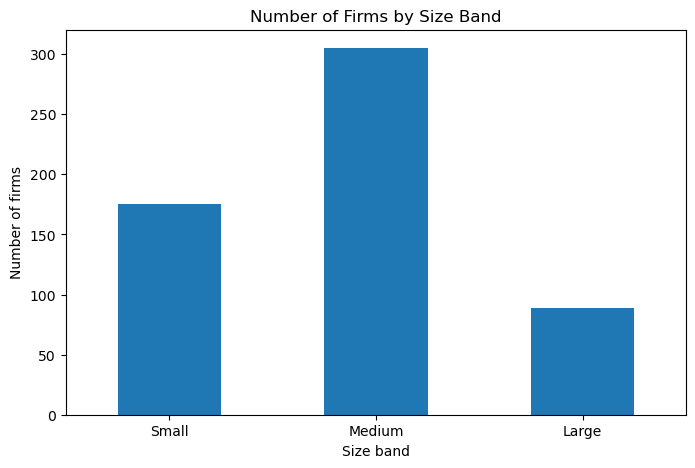

Medium    305
Small     175
Large      89
Name: size_band, dtype: int64


In [10]:
# 2. Bar chart of size_band in the order Small, Medium, Large (demo 2.3)

plt.figure(figsize=(8, 5))
df["size_band"].value_counts().reindex(size_order).plot(kind="bar")
plt.title("Number of Firms by Size Band")
plt.xlabel("Size band")
plt.ylabel("Number of firms")
plt.xticks(rotation=0)
plt.show()

# The order that .value_counts() alone would give
print(df["size_band"].value_counts())

**Correct answer: Medium firms are the most numerous, followed by Small and Large. Without `.reindex(size_order)` the bars would be sorted by frequency: Medium, Small, Large.**

### Commentary

`.value_counts()` always sorts by the count, so the scale from small to large would be
broken: the printed table shows the order Medium, Small, Large.

For the delegation: more than half of the firms are medium-sized, and only about one firm
in six is large. The meetings should be prepared for mid-sized firms, which confirms the
conclusion of seminar 2.

### Task 3. Do larger firms pay more?

Draw box plots of `wage` by `size_band`, with the boxes in the order Small, Medium, Large.

*Question:* compare the three medians. In which size band are wages highest? Is the
difference between Small and Medium large or small?

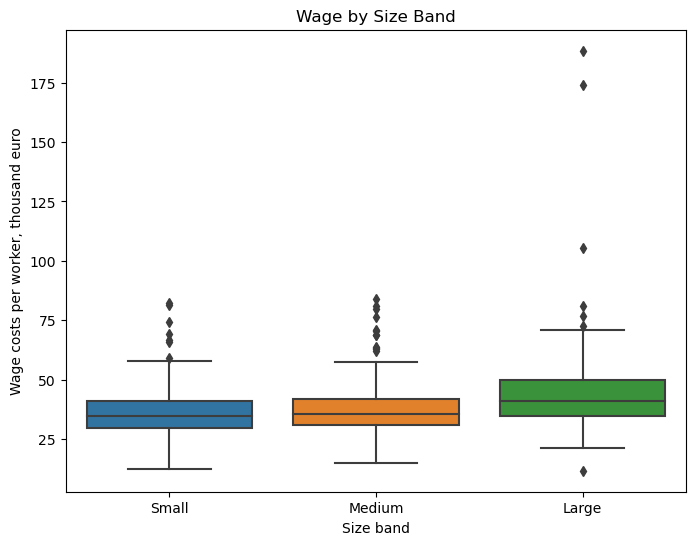

In [11]:
# 3. Box plots of wage by size band, in the order of size_order (demo 3.2)

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="size_band", y="wage", order=size_order)
plt.title("Wage by Size Band")
plt.xlabel("Size band")
plt.ylabel("Wage costs per worker, thousand euro")
plt.show()

**Correct answer: wages are highest in large firms (median 41.25 thousand euro). The medians of small and medium firms are almost the same: 34.90 and 35.68.**

### Commentary

On the chart the median line of the Large box is clearly higher than the other two, while
the Small and Medium lines are nearly level. Approximate values read off the chart
(about 35, 36 and 41) are a full answer.

All three groups have dots far above their boxes: in every size band some firms pay much
more than the rest.

For the delegation: "labour in Belgium is expensive" is mostly a statement about large firms.
In small and medium firms a worker costs about 35-36 thousand euro, in large firms about 41.

### Task 4. Do firms with more workers produce more?

Draw a scatter plot of `labour` against `output`. Draw it a second time with the dots
coloured by size band.

*Question:* do firms with more workers produce more? Find the dot that lies far to the right
of all the others: approximately how many workers does this firm have, and to which size band
does it belong?

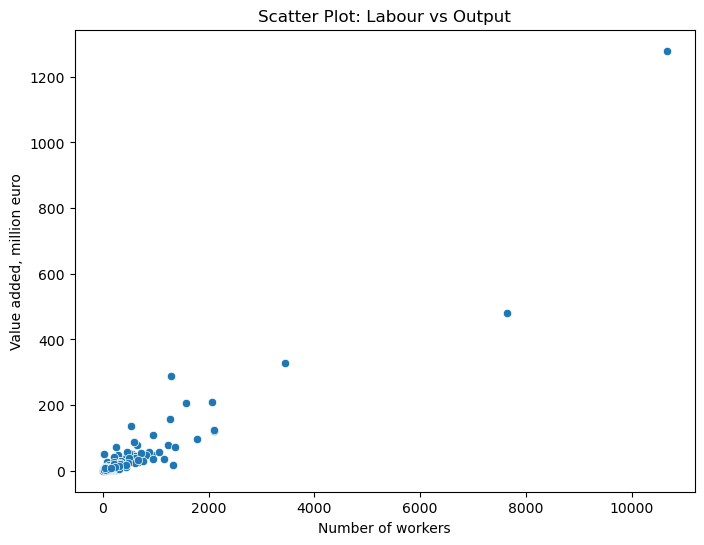

In [12]:
# 4.1 Scatter plot of labour against output (demo 3.1)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="labour", y="output")
plt.title("Scatter Plot: Labour vs Output")
plt.xlabel("Number of workers")
plt.ylabel("Value added, million euro")
plt.show()

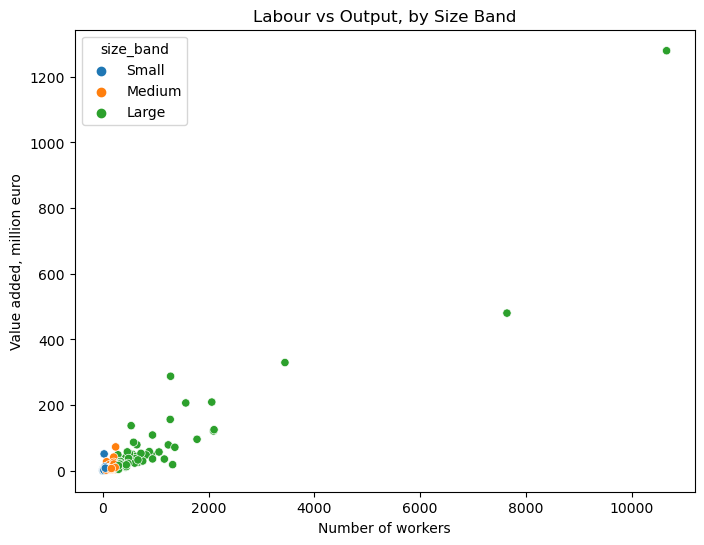

In [13]:
# 4.2 The same scatter plot, coloured by size band (Cheat Sheet #3, "Grouped scatter plot with hue")

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="labour", y="output", hue="size_band", hue_order=size_order)
plt.title("Labour vs Output, by Size Band")
plt.xlabel("Number of workers")
plt.ylabel("Value added, million euro")
plt.show()

**Correct answer: yes, firms with more workers produce more: the dots rise from left to right. The dot far to the right is a large firm with about 10,000 workers (exactly 10,661) and a value added of about 1,300 million euro (exactly 1,279.37).**

### Commentary

Most firms are pressed into the lower left corner, because one firm is so much bigger than
the others that it stretches both axes. This is the concentration found in seminar 2, now
visible at a glance. An approximate reading of the position of the dot is a full answer.

The colours show that the size bands are slices of the horizontal axis: Small on the very
left, Medium next to it, Large spread over the rest.

For the delegation: one firm in the sample is in a class of its own, and a meeting with it
deserves separate preparation.

### Task 5. What goes together with what?

Select the four numerical columns, compute the correlation matrix and draw it as a heatmap
with the numbers in the cells, the colour map `"coolwarm"` and the colour scale from -1 to 1.

*Question:* which pair of columns has the strongest correlation? How strong is the correlation
between `wage` and `output`? Do higher wages go together with higher output?

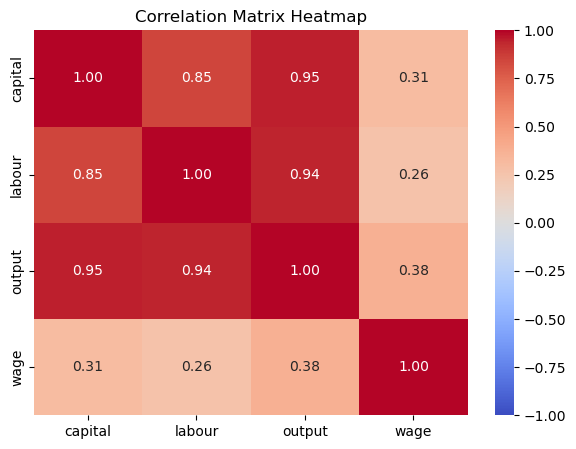

In [14]:
# 5. Correlation heatmap of the four numerical columns (demo 4.2)

num_df = df[["capital", "labour", "output", "wage"]]
corr_matrix = num_df.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix Heatmap")
plt.show()

**Correct answer: the strongest pair is `capital` and `output` (0.95), followed by `labour` and `output` (0.94) and `capital` and `labour` (0.85). The correlation between `wage` and `output` is only 0.38: higher wages go together with higher output, but weakly.**

### Commentary

The three size measures, `capital`, `labour` and `output`, form a dark red block: a large firm
is large in every respect. The `wage` row is much paler: 0.31 with capital, 0.26 with labour,
0.38 with output.

For the delegation: firms that produce more pay somewhat more per worker, but the link is weak.